In [1]:
import pandas as pd
import os

In [2]:
data_path = "../data/raw"

print(os.listdir(data_path))


['.ipynb_checkpoints', 'train_identity.csv', 'train_transaction.csv']


In [3]:
transaction_sample = pd.read_csv(
    "../data/raw/train_transaction.csv",
    nrows=1000
)

transaction_sample.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
print("Rows:", transaction_sample.shape[0])
print("Columns:", transaction_sample.shape[1])

Rows: 1000
Columns: 394


In [5]:
transaction_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 3.0+ MB


In [6]:
transaction_sample.shape

(1000, 394)

In [7]:
transaction_sample["isFraud"].value_counts()

isFraud
0    985
1     15
Name: count, dtype: int64

In [8]:
transaction_sample["isFraud"].value_counts(normalize=True)*100

isFraud
0    98.5
1     1.5
Name: proportion, dtype: float64

In [9]:
important_columns = [
    "TransactionID",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "P_emaildomain",
    "R_emaildomain",
    "isFraud"
]

transaction_sample[important_columns].head()

,TransactionID,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,P_emaildomain,R_emaildomain,isFraud
0,2987000,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,NaN,NaN,0
1,2987001,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,gmail.com,NaN,0
2,2987002,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,outlook.com,NaN,0
3,2987003,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,yahoo.com,NaN,0
4,2987004,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,gmail.com,NaN,0


In [10]:
transaction_sample[important_columns].dtypes

TransactionID       int64
TransactionDT       int64
TransactionAmt    float64
ProductCD          object
card1               int64
card2             float64
card3             float64
card4              object
card5             float64
card6              object
addr1             float64
addr2             float64
P_emaildomain      object
R_emaildomain      object
isFraud             int64
dtype: object

In [11]:
missing = transaction_sample.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing.head(20)

D7       934
dist2    908
D13      863
D14      861
D9       861
D8       861
V335     847
V337     847
V336     847
V338     847
V339     847
V158     847
V157     847
V164     847
V152     847
V153     847
V326     847
V324     847
V325     847
V323     847
dtype: int64

In [12]:
missing_percent = (transaction_sample.isnull().mean() * 100)

missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

missing_percent.head(20)

D7       93.4
dist2    90.8
D13      86.3
D14      86.1
D9       86.1
D8       86.1
V335     84.7
V337     84.7
V336     84.7
V338     84.7
V339     84.7
V158     84.7
V157     84.7
V164     84.7
V152     84.7
V153     84.7
V326     84.7
V324     84.7
V325     84.7
V323     84.7
dtype: float64

In [13]:
transaction_sample.groupby("isFraud")["TransactionAmt"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,985.0,159.930593,341.327351,1.896,39.000,60.00,140.0000,3162.95
1,15.0,143.429000,208.486366,10.000,24.712,83.38,139.9325,774.00


In [14]:
transaction_sample["TransactionDT"].head(10)

0    86400
1    86401
2    86469
3    86499
4    86506
5    86510
6    86522
7    86529
8    86535
9    86536
Name: TransactionDT, dtype: int64

In [15]:
transaction_sample["TransactionDT"].describe()

count      1000.00000
mean      96340.39500
std        7042.11914
min       86400.00000
25%       90330.75000
50%       94863.50000
75%      100976.00000
max      112151.00000
Name: TransactionDT, dtype: float64

In [16]:
time_difference = (
    transaction_sample["TransactionDT"].max()
    - transaction_sample["TransactionDT"].min()
)

print("Time difference in seconds:", time_difference)
print("Time difference in hours:", time_difference / 3600)
print("Time difference in days:", time_difference / 86400)

Time difference in seconds: 25751
Time difference in hours: 7.1530555555555555
Time difference in days: 0.2980439814814815


In [17]:
transaction_time = pd.read_csv(
    "../data/raw/train_transaction.csv",
    usecols=["TransactionDT"]
)

print("Minimum TransactionDT:", transaction_time["TransactionDT"].min())
print("Maximum TransactionDT:", transaction_time["TransactionDT"].max())

Minimum TransactionDT: 86400
Maximum TransactionDT: 15811131


In [18]:
time_range = (
    transaction_time["TransactionDT"].max()
    - transaction_time["TransactionDT"].min()
)

print("Total time in seconds:", time_range)
print("Total time in hours:", time_range / 3600)
print("Total time in days:", time_range / 86400)

Total time in seconds: 15724731
Total time in hours: 4367.980833333333
Total time in days: 181.99920138888888


In [19]:
identity_sample = pd.read_csv(
    "../data/raw/train_identity.csv",
    nrows=1000
)

print("Rows:", identity_sample.shape[0])
print("Columns:", identity_sample.shape[1])

Rows: 1000
Columns: 41


In [20]:
identity_sample.head()


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [21]:
identity_missing = identity_sample.isnull().sum()

identity_missing = identity_missing[
    identity_missing > 0
].sort_values(ascending=False)

identity_missing.head(20)

id_24    965
id_07    964
id_21    964
id_23    964
id_08    964
id_22    964
id_26    964
id_27    964
id_25    964
id_18    703
id_03    562
id_04    562
id_09    466
id_10    466
id_33    412
id_34    382
id_32    369
id_30    369
id_14    347
id_13    216
dtype: int64

In [22]:
print("Transaction IDs in transaction data:", transaction_sample["TransactionID"].nunique())
print("Transaction IDs in identity data:", identity_sample["TransactionID"].nunique())

Transaction IDs in transaction data: 1000
Transaction IDs in identity data: 1000


In [23]:
common_ids = set(transaction_sample["TransactionID"]) & set(identity_sample["TransactionID"])

print("Common TransactionIDs:", len(common_ids))

Common TransactionIDs: 296


In [24]:
merged_sample = transaction_sample.merge(
    identity_sample,
    on="TransactionID",
    how="left"
)

print("Rows:", merged_sample.shape[0])
print("Columns:", merged_sample.shape[1])

Rows: 1000
Columns: 434


In [25]:
merged_sample[["TransactionID","isFraud","DeviceType","DeviceInfo"]].head(10)


,TransactionID,isFraud,DeviceType,DeviceInfo
0,2987000,0,NaN,NaN
1,2987001,0,NaN,NaN
2,2987002,0,NaN,NaN
3,2987003,0,NaN,NaN
4,2987004,0,mobile,SAMSUNG SM-G892A Build/NRD90M
5,2987005,0,NaN,NaN
6,2987006,0,NaN,NaN
7,2987007,0,NaN,NaN
8,2987008,0,mobile,iOS Device
9,2987009,0,NaN,NaN


In [26]:
merged_sample["has_identity"] = (
    merged_sample["DeviceType"].notna().astype(int)
)

In [27]:
# Show transaction columns grouped by their prefix/name

for col in transaction_sample.columns:
    print(col)

TransactionID
isFraud
TransactionDT
TransactionAmt
ProductCD
card1
card2
card3
card4
card5
card6
addr1
addr2
dist1
dist2
P_emaildomain
R_emaildomain
C1
C2
C3
C4
C5
C6
C7
C8
C9
C10
C11
C12
C13
C14
D1
D2
D3
D4
D5
D6
D7
D8
D9
D10
D11
D12
D13
D14
D15
M1
M2
M3
M4
M5
M6
M7
M8
M9
V1
V2
V3
V4
V5
V6
V7
V8
V9
V10
V11
V12
V13
V14
V15
V16
V17
V18
V19
V20
V21
V22
V23
V24
V25
V26
V27
V28
V29
V30
V31
V32
V33
V34
V35
V36
V37
V38
V39
V40
V41
V42
V43
V44
V45
V46
V47
V48
V49
V50
V51
V52
V53
V54
V55
V56
V57
V58
V59
V60
V61
V62
V63
V64
V65
V66
V67
V68
V69
V70
V71
V72
V73
V74
V75
V76
V77
V78
V79
V80
V81
V82
V83
V84
V85
V86
V87
V88
V89
V90
V91
V92
V93
V94
V95
V96
V97
V98
V99
V100
V101
V102
V103
V104
V105
V106
V107
V108
V109
V110
V111
V112
V113
V114
V115
V116
V117
V118
V119
V120
V121
V122
V123
V124
V125
V126
V127
V128
V129
V130
V131
V132
V133
V134
V135
V136
V137
V138
V139
V140
V141
V142
V143
V144
V145
V146
V147
V148
V149
V150
V151
V152
V153
V154
V155
V156
V157
V158
V159
V160
V161
V162
V163
V164
V165
V166
V167

In [28]:
print("Card columns:")
print([col for col in transaction_sample.columns if col.startswith("card")])


Card columns:
['card1', 'card2', 'card3', 'card4', 'card5', 'card6']


In [29]:
print("Address columns:")
print([col for col in transaction_sample.columns if col.startswith("addr")])

Address columns:
['addr1', 'addr2']


In [30]:
print("Distance columns:")
print([col for col in transaction_sample.columns if col.startswith("dist")])

Distance columns:
['dist1', 'dist2']


In [31]:
print("Email columns:")
print([col for col in transaction_sample.columns if "email" in col.lower()])

Email columns:
['P_emaildomain', 'R_emaildomain']


In [32]:
print("D columns:")
print([col for col in transaction_sample.columns if col.startswith("D")])

D columns:
['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15']


In [33]:
transaction_features = [
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",

    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6",

    "addr1",
    "addr2",

    "dist1",
    "dist2",

    "P_emaildomain",
    "R_emaildomain",

    "isFraud"
]

In [34]:
transaction_sample[transaction_features].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TransactionDT   1000 non-null   int64  
 1   TransactionAmt  1000 non-null   float64
 2   ProductCD       1000 non-null   object 
 3   card1           1000 non-null   int64  
 4   card2           974 non-null    float64
 5   card3           1000 non-null   float64
 6   card4           1000 non-null   object 
 7   card5           999 non-null    float64
 8   card6           1000 non-null   object 
 9   addr1           837 non-null    float64
 10  addr2           837 non-null    float64
 11  dist1           365 non-null    float64
 12  dist2           92 non-null     float64
 13  P_emaildomain   838 non-null    object 
 14  R_emaildomain   239 non-null    object 
 15  isFraud         1000 non-null   int64  
dtypes: float64(8), int64(3), object(5)
memory usage: 125.1+ KB


In [35]:
transaction_sample[transaction_features].isnull().sum()

TransactionDT       0
TransactionAmt      0
ProductCD           0
card1               0
card2              26
card3               0
card4               0
card5               1
card6               0
addr1             163
addr2             163
dist1             635
dist2             908
P_emaildomain     162
R_emaildomain     761
isFraud             0
dtype: int64

In [36]:
transaction_sample["day_index"]=(
    transaction_sample["TransactionDT"]//86400
)
transaction_sample["hour"]=(
    (transaction_sample["TransactionDT"]%86400)//3600
)
transaction_sample["minute"]=(
    (transaction_sample["TransactionDT"]%86400)//60
)

In [37]:
transaction_sample[
    ["TransactionDT", "day_index", "hour", "minute"]
].head(10)

,TransactionDT,day_index,hour,minute
0,86400,1,0,0
1,86401,1,0,0
2,86469,1,0,1
3,86499,1,0,1
4,86506,1,0,1
5,86510,1,0,1
6,86522,1,0,2
7,86529,1,0,2
8,86535,1,0,2
9,86536,1,0,2


In [38]:
categorical_columns = [
    "ProductCD",
    "card4",
    "card6",
    "P_emaildomain",
    "R_emaildomain",
]
for col in categorical_columns:
    print("\n", col)
    print(transaction_sample[col].value_counts().head(10))


 ProductCD
ProductCD
W    686
C    161
H     98
R     29
S     26
Name: count, dtype: int64

 card4
card4
visa                648
mastercard          334
american express     10
discover              8
Name: count, dtype: int64

 card6
card6
debit     723
credit    277
Name: count, dtype: int64

 P_emaildomain
P_emaildomain
gmail.com        355
yahoo.com        190
hotmail.com       79
anonymous.com     59
aol.com           47
comcast.net       16
icloud.com        10
outlook.com        9
yahoo.com.mx       8
msn.com            8
Name: count, dtype: int64

 R_emaildomain
R_emaildomain
gmail.com        87
hotmail.com      53
anonymous.com    48
yahoo.com        11
yahoo.com.mx      8
outlook.com       7
icloud.com        4
live.com.mx       4
comcast.net       4
aol.com           2
Name: count, dtype: int64


In [39]:
for col in categorical_columns:
    print(col, "→", transaction_sample[col].nunique(), "unique values")

ProductCD → 5 unique values
card4 → 4 unique values
card6 → 2 unique values
P_emaildomain → 34 unique values
R_emaildomain → 20 unique values


In [40]:
for col in categorical_columns:
    print("\n"+col)
    print(transaction_sample[col].unique())
    


ProductCD
['W' 'H' 'C' 'S' 'R']

card4
['discover' 'mastercard' 'visa' 'american express']

card6
['credit' 'debit']

P_emaildomain
[nan 'gmail.com' 'outlook.com' 'yahoo.com' 'mail.com' 'anonymous.com'
 'hotmail.com' 'verizon.net' 'aol.com' 'me.com' 'comcast.net'
 'optonline.net' 'cox.net' 'charter.net' 'rocketmail.com' 'prodigy.net.mx'
 'embarqmail.com' 'icloud.com' 'live.com.mx' 'gmail' 'live.com' 'att.net'
 'juno.com' 'ymail.com' 'sbcglobal.net' 'bellsouth.net' 'msn.com' 'q.com'
 'yahoo.com.mx' 'centurylink.net' 'servicios-ta.com' 'earthlink.net'
 'hotmail.es' 'cfl.rr.com' 'roadrunner.com']

R_emaildomain
[nan 'gmail.com' 'hotmail.com' 'outlook.com' 'anonymous.com' 'charter.net'
 'prodigy.net.mx' 'comcast.net' 'live.com.mx' 'icloud.com' 'yahoo.com'
 'aol.com' 'juno.com' 'att.net' 'verizon.net' 'yahoo.com.mx'
 'bellsouth.net' 'servicios-ta.com' 'ymail.com' 'hotmail.es' 'msn.com']


In [41]:
numerical_columns = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "dist2",
    "day_index",
    "hour",
    "minute",
]    

print("Number of numerical features:", len(numerical_columns))

Number of numerical features: 13


In [42]:
transaction_sample[numerical_columns].isnull().sum()

TransactionDT       0
TransactionAmt      0
card1               0
card2              26
card3               0
card5               1
addr1             163
addr2             163
dist1             635
dist2             908
day_index           0
hour                0
minute              0
dtype: int64

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [44]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

In [45]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [46]:
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

In [47]:
X=transaction_sample[numerical_columns+categorical_columns]
y=transaction_sample["isFraud"]

In [48]:
X.shape

(1000, 18)

In [49]:
y.shape

(1000,)

In [50]:
print(y.value_counts())

isFraud
0    985
1     15
Name: count, dtype: int64


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [52]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 18)
X_test: (200, 18)
y_train: (800,)
y_test: (200,)


In [53]:
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training target distribution:
isFraud
0    98.5
1     1.5
Name: proportion, dtype: float64

Testing target distribution:
isFraud
0    98.5
1     1.5
Name: proportion, dtype: float64


In [54]:
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [55]:
baseline_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['TransactionDT','TransactionAmt','card1',...,'card6','P_emaildomain', 'R_emaildomain']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [56]:
print("Baseline model trained successfully.")

Baseline model trained successfully.


In [57]:
y_pred = baseline_model.predict(X_test)
print(y_pred)

[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]


In [58]:
y_prob = baseline_model.predict_proba(X_test)[:, 1]
print(y_prob)

[9.66764907e-05 1.35038263e-03 7.53492559e-04 4.06861930e-04
 4.62823532e-02 3.13118280e-05 2.04336132e-03 4.50088640e-03
 7.27721395e-05 7.75469734e-01 1.12020423e-04 2.62985875e-05
 1.14863660e-03 2.07130911e-02 8.75216101e-04 6.65742017e-01
 5.41452450e-01 3.46921195e-04 1.21818080e-03 6.87326319e-01
 1.22532428e-03 2.75551129e-05 2.05907593e-03 1.38947595e-04
 4.51833340e-03 3.27492759e-02 1.69726056e-03 3.29736438e-03
 1.88599992e-03 3.66158497e-05 7.15922605e-05 4.15571334e-03
 5.55373893e-04 1.98404024e-05 1.46817974e-04 5.62428564e-05
 1.45358582e-04 3.59591195e-03 5.25104779e-05 3.02229143e-03
 9.55213146e-05 4.47358348e-04 2.27662691e-04 1.75817462e-04
 5.04523954e-03 2.92557458e-03 3.40297634e-04 1.31543505e-03
 2.56720703e-03 3.70725582e-04 3.96475140e-03 6.57807526e-03
 1.09591785e-04 6.35569357e-04 8.10948021e-02 8.63096862e-04
 5.13130317e-02 3.60844181e-03 1.53443152e-03 3.06000544e-05
 4.89832502e-04 5.77638728e-01 3.69525749e-04 4.79529092e-04
 2.63996497e-05 1.758353

In [59]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

Confusion Matrix:
[[182  15]
 [  3   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.92      0.95       197
           1       0.00      0.00      0.00         3

    accuracy                           0.91       200
   macro avg       0.49      0.46      0.48       200
weighted avg       0.97      0.91      0.94       200

ROC-AUC: 0.37394247038917083
PR-AUC: 0.015489095367144146


input incresed to 50000

In [60]:
transaction_data = pd.read_csv(
    "../data/raw/train_transaction.csv",
    nrows=50000
)

print("Shape:", transaction_data.shape)
print("\nFraud distribution:")
print(transaction_data["isFraud"].value_counts())
print("\nFraud percentage:")
print(transaction_data["isFraud"].mean() * 100)

Shape: (50000, 394)

Fraud distribution:
isFraud
0    48643
1     1357
Name: count, dtype: int64

Fraud percentage:
2.714


In [61]:
transaction_data["day_index"] = (
    transaction_data["TransactionDT"] // 86400
)

transaction_data["hour"] = (
    (transaction_data["TransactionDT"] % 86400) // 3600
)

transaction_data["minute"] = (
    (transaction_data["TransactionDT"] % 3600) // 60
)

print("Time features created successfully.")

Time features created successfully.


In [62]:
X = transaction_data[
    numerical_columns+ categorical_columns
]

y = transaction_data["isFraud"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50000, 18)
y shape: (50000,)


In [63]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining fraud rate:", y_train.mean() * 100)
print("Testing fraud rate:", y_test.mean() * 100)

Training data: (40000, 18)
Testing data: (10000, 18)

Training fraud rate: 2.715
Testing fraud rate: 2.71


In [64]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=50000,
        class_weight="balanced"
    ))
])

In [65]:
baseline_model.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['TransactionDT','TransactionAmt','card1',...,'card6','P_emaildomain', 'R_emaildomain']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [66]:
print("Baseline model trained successfully.")

Baseline model trained successfully.


In [67]:
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [68]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

Confusion Matrix:
[[7569 2160]
 [  97  174]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.78      0.87      9729
           1       0.07      0.64      0.13       271

    accuracy                           0.77     10000
   macro avg       0.53      0.71      0.50     10000
weighted avg       0.96      0.77      0.85     10000

ROC-AUC: 0.7606960435931834
PR-AUC: 0.1307064161863628


In [69]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

for threshold in thresholds:
    y_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_threshold, zero_division=0)
    recall = recall_score(y_test, y_threshold, zero_division=0)
    f1 = f1_score(y_test, y_threshold, zero_division=0)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.10 | Precision: 0.028 | Recall: 0.993 | F1: 0.055
Threshold: 0.20 | Precision: 0.030 | Recall: 0.993 | F1: 0.058
Threshold: 0.30 | Precision: 0.034 | Recall: 0.923 | F1: 0.066
Threshold: 0.40 | Precision: 0.048 | Recall: 0.738 | F1: 0.091
Threshold: 0.50 | Precision: 0.075 | Recall: 0.642 | F1: 0.134
Threshold: 0.60 | Precision: 0.091 | Recall: 0.517 | F1: 0.155
Threshold: 0.70 | Precision: 0.118 | Recall: 0.384 | F1: 0.180
Threshold: 0.80 | Precision: 0.177 | Recall: 0.310 | F1: 0.225
Threshold: 0.90 | Precision: 0.288 | Recall: 0.125 | F1: 0.175


In [70]:
identity_data = pd.read_csv(
    "../data/raw/train_identity.csv"
)

print("Identity shape:", identity_data.shape)

Identity shape: (144233, 41)


In [71]:
print(identity_data[[
    "TransactionID",
    "DeviceType",
    "DeviceInfo"
]].head())

print("\nIdentity columns:")
print(identity_data.columns.tolist())

   TransactionID DeviceType                     DeviceInfo
0        2987004     mobile  SAMSUNG SM-G892A Build/NRD90M
1        2987008     mobile                     iOS Device
2        2987010    desktop                        Windows
3        2987011    desktop                            NaN
4        2987016    desktop                          MacOS

Identity columns:
['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [72]:
identity_subset = identity_data[
    identity_data["TransactionID"].isin(
        transaction_data["TransactionID"]
    )
].copy()

print("Identity subset shape:", identity_subset.shape)

Identity subset shape: (16456, 41)


In [73]:
transaction_data = transaction_data.merge(
    identity_subset,
    on="TransactionID",
    how="left"
)

print("Merged shape:", transaction_data.shape)

Merged shape: (50000, 437)


In [74]:
transaction_data["has_identity"]=(
    transaction_data["DeviceType"].notna().astype(int)
)

print(transaction_data["has_identity"].value_counts())


has_identity
0    33932
1    16068
Name: count, dtype: int64


In [75]:
print(transaction_data["DeviceType"].value_counts(dropna=False))

DeviceType
NaN        33932
desktop    10887
mobile      5181
Name: count, dtype: int64


In [76]:
transaction_data["DeviceType"]=transaction_data["DeviceType"].fillna("unknown")
print(transaction_data["DeviceType"].value_counts())

DeviceType
unknown    33932
desktop    10887
mobile      5181
Name: count, dtype: int64


In [77]:
print("Unique Deviceinfo values:",transaction_data["DeviceInfo"].nunique())

print("\n Top DeviceInfo values: ")
print(transaction_data["DeviceInfo"].value_counts().head(15))


Unique Deviceinfo values: 585

 Top DeviceInfo values: 
DeviceInfo
Windows                  6224
iOS Device               2660
MacOS                    1904
Trident/7.0              1143
rv:11.0                   239
rv:57.0                   160
rv:52.0                    58
SM-G950U Build/NRD90M      56
rv:48.0                    47
SM-G930V Build/NRD90M      45
SM-J700M Build/MMB29K      34
SM-G935F Build/NRD90M      30
SM-G955U Build/NRD90M      29
SM-G610M Build/MMB29K      28
SM-G531H Build/LMY48B      25
Name: count, dtype: int64


In [78]:
def get_device_family(device):
    if pd.isna(device):
        return "unknown"

    device = str(device).lower()

    if "samsung" in device or "sm-" in device:
        return "samsung"
    elif "ios" in device or "iphone" in device or "ipad" in device:
        return "ios"
    elif "windows" in device:
        return "windows"
    elif "mac" in device:
        return "mac"
    elif "android" in device:
        return "android"
    elif "trident" in device:
        return "trident"
    elif "chrome" in device:
        return "chrome"
    elif "firefox" in device:
        return "firefox"
    else:
        return "other"


transaction_data["device_family"] = (
    transaction_data["DeviceInfo"].apply(get_device_family)
)

print(transaction_data["device_family"].value_counts())

device_family
unknown    35649
windows     6240
ios         2660
mac         1904
other       1491
trident     1143
samsung      908
android        5
Name: count, dtype: int64


In [79]:
numerical_columns_new = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "dist2",
    "day_index",
    "hour",
    "minute",
    "has_identity"
]

categorical_columns_new= [
    "ProductCD",
    "card4",
    "card6",
    "P_emaildomain",
    "R_emaildomain",
    "DeviceType",
    "device_family"
]

In [80]:
X = transaction_data[
    numerical_columns_new+ categorical_columns_new
]

y = transaction_data["isFraud"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50000, 21)
y shape: (50000,)


In [81]:
numerical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor=ColumnTransformer([
    ("num",numerical_pipeline,numerical_columns_new),
    ("cat",categorical_pipeline,categorical_columns_new)
])

print("Preprocessing pipeline created succesfully")

Preprocessing pipeline created succesfully


In [82]:
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

print("Baseline model created successfully.")

Baseline model created successfully.


In [83]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 21)
Testing data: (10000, 21)


In [84]:
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully.")


Baseline model trained successfully.


In [85]:
y_pred = baseline_model.predict(X_test)

y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully.")

Predictions completed successfully.


In [86]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

Confusion Matrix:
[[7592 2137]
 [  88  183]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.78      0.87      9729
           1       0.08      0.68      0.14       271

    accuracy                           0.78     10000
   macro avg       0.53      0.73      0.51     10000
weighted avg       0.96      0.78      0.85     10000

ROC-AUC: 0.7697096859960275
PR-AUC: 0.12650122567666908


In [87]:
baseline_results = {
    "Model": "Logistic Regression",
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob)
}

print(baseline_results)

{'Model': 'Logistic Regression', 'ROC-AUC': 0.7697096859960275, 'PR-AUC': 0.12650122567666908}


In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

xgb_preprocessor = ColumnTransformer([
    (
        "num",SimpleImputer(strategy="median"),numerical_columns_new),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_columns_new
    )
])

print("XGBoost preprocessing created successfully.")

XGBoost preprocessing created successfully.


In [89]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("XGBoost model created successfully.")

XGBoost model created successfully.


In [90]:
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [91]:
xgb_pred = xgb_model.predict(X_test)

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions completed successfully.")

XGBoost predictions completed successfully.


In [92]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))
print("PR-AUC:", average_precision_score(y_test, xgb_prob))

Confusion Matrix:
[[9725    4]
 [ 203   68]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      9729
           1       0.94      0.25      0.40       271

    accuracy                           0.98     10000
   macro avg       0.96      0.63      0.69     10000
weighted avg       0.98      0.98      0.97     10000

ROC-AUC: 0.9028024785335735
PR-AUC: 0.5809669427023452


In [93]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [
    0.10, 0.20, 0.30, 0.40,
    0.50, 0.60, 0.70, 0.80, 0.90
]

for threshold in thresholds:
    y_threshold = (xgb_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_threshold,
        zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.10 | Precision: 0.404 | Recall: 0.605 | F1: 0.484
Threshold: 0.20 | Precision: 0.608 | Recall: 0.520 | F1: 0.561
Threshold: 0.30 | Precision: 0.763 | Recall: 0.439 | F1: 0.557
Threshold: 0.40 | Precision: 0.864 | Recall: 0.351 | F1: 0.499
Threshold: 0.50 | Precision: 0.944 | Recall: 0.251 | F1: 0.397
Threshold: 0.60 | Precision: 0.981 | Recall: 0.196 | F1: 0.326
Threshold: 0.70 | Precision: 1.000 | Recall: 0.114 | F1: 0.205
Threshold: 0.80 | Precision: 1.000 | Recall: 0.070 | F1: 0.131
Threshold: 0.90 | Precision: 1.000 | Recall: 0.011 | F1: 0.022


In [94]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "XGBoost",
        "ROC-AUC": roc_auc_score(y_test, xgb_prob),
        "PR-AUC": average_precision_score(y_test, xgb_prob)
    }
])

print(model_comparison)

                 Model   ROC-AUC    PR-AUC
0  Logistic Regression  0.769710  0.126501
1              XGBoost  0.902802  0.580967


In [95]:
from xgboost import XGBClassifier

xgb_tuned = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", XGBClassifier(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.05,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("Tuned XGBoost model created successfully.")

Tuned XGBoost model created successfully.


In [96]:
xgb_tuned.fit(X_train, y_train)

print("Tuned XGBoost model trained successfully.")

Tuned XGBoost model trained successfully.


In [97]:
xgb_tuned_pred = xgb_tuned.predict(X_test)
xgb_tuned_prob = xgb_tuned.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [98]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_tuned_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_tuned_pred))

print("ROC-AUC:", roc_auc_score(y_test, xgb_tuned_prob))
print("PR-AUC:", average_precision_score(y_test, xgb_tuned_prob))

Confusion Matrix:
[[9725    4]
 [ 207   64]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      9729
           1       0.94      0.24      0.38       271

    accuracy                           0.98     10000
   macro avg       0.96      0.62      0.68     10000
weighted avg       0.98      0.98      0.97     10000

ROC-AUC: 0.8915135219807332
PR-AUC: 0.5491375002745815


In [99]:
final_model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Original XGBoost",
        "ROC-AUC": roc_auc_score(y_test, xgb_prob),
        "PR-AUC": average_precision_score(y_test, xgb_prob)
    },
    {
        "Model": "Tuned XGBoost",
        "ROC-AUC": roc_auc_score(y_test, xgb_tuned_prob),
        "PR-AUC": average_precision_score(y_test, xgb_tuned_prob)
    }
])

print(final_model_comparison)

                 Model   ROC-AUC    PR-AUC
0  Logistic Regression  0.769710  0.126501
1     Original XGBoost  0.902802  0.580967
2        Tuned XGBoost  0.891514  0.549138


In [100]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Normal transactions:", negative_count)
print("Fraud transactions:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Normal transactions: 38914
Fraud transactions: 1086
Scale Pos Weight: 35.83241252302026


In [101]:
xgb_balanced = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("Imbalance-aware XGBoost model created successfully.")

Imbalance-aware XGBoost model created successfully.


In [102]:
xgb_balanced.fit(X_train, y_train)

print("Imbalance-aware XGBoost model trained successfully.")

Imbalance-aware XGBoost model trained successfully.


In [103]:
xgb_balanced_pred = xgb_balanced.predict(X_test)
xgb_balanced_prob = xgb_balanced.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [104]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_balanced_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_balanced_pred))

print("ROC-AUC:", roc_auc_score(y_test, xgb_balanced_prob))
print("PR-AUC:", average_precision_score(y_test, xgb_balanced_prob))

Confusion Matrix:
[[9191  538]
 [  79  192]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      9729
           1       0.26      0.71      0.38       271

    accuracy                           0.94     10000
   macro avg       0.63      0.83      0.68     10000
weighted avg       0.97      0.94      0.95     10000

ROC-AUC: 0.8977053045276059
PR-AUC: 0.515193833634794


In [105]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    
    threshold_pred = (xgb_prob >= threshold).astype(int)
    
    precision = precision_score(y_test, threshold_pred)
    recall = recall_score(y_test, threshold_pred)
    f1 = f1_score(y_test, threshold_pred)
    
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_results_df = pd.DataFrame(threshold_results)

print(threshold_results_df)

   Threshold  Precision    Recall        F1
0        0.1   0.403941  0.605166  0.484490
1        0.2   0.607759  0.520295  0.560636
2        0.3   0.762821  0.439114  0.557377
3        0.4   0.863636  0.350554  0.498688
4        0.5   0.944444  0.250923  0.396501
5        0.6   0.981481  0.195572  0.326154
6        0.7   1.000000  0.114391  0.205298
7        0.8   1.000000  0.070111  0.131034
8        0.9   1.000000  0.011070  0.021898


In [106]:
best_threshold = threshold_results_df.loc[
    threshold_results_df["F1"].idxmax()
]

print("Best threshold:")
print(best_threshold)

Best threshold:
Threshold    0.200000
Precision    0.607759
Recall       0.520295
F1           0.560636
Name: 1, dtype: float64


In [107]:
X_test_transformed = xgb_preprocessor.transform(X_test)

feature_names = xgb_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.named_steps["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance.head(20))

                              Feature  Importance
14                   cat__ProductCD_C    0.104918
4                          num__card3    0.095711
103      cat__R_emaildomain_gmail.com    0.046045
25                  cat__card6_credit    0.038127
26                   cat__card6_debit    0.026827
30   cat__P_emaildomain_anonymous.com    0.026050
146            cat__DeviceType_mobile    0.024018
52      cat__P_emaildomain_icloud.com    0.022684
64     cat__P_emaildomain_outlook.com    0.022368
18                   cat__ProductCD_W    0.022203
16                   cat__ProductCD_R    0.017032
45       cat__P_emaildomain_gmail.com    0.016895
145           cat__DeviceType_desktop    0.016129
13                  num__has_identity    0.015991
48     cat__P_emaildomain_hotmail.com    0.015469
139      cat__R_emaildomain_yahoo.com    0.015382
77         cat__P_emaildomain_unknown    0.015117
133        cat__R_emaildomain_unknown    0.015058
20                cat__card4_discover    0.014854


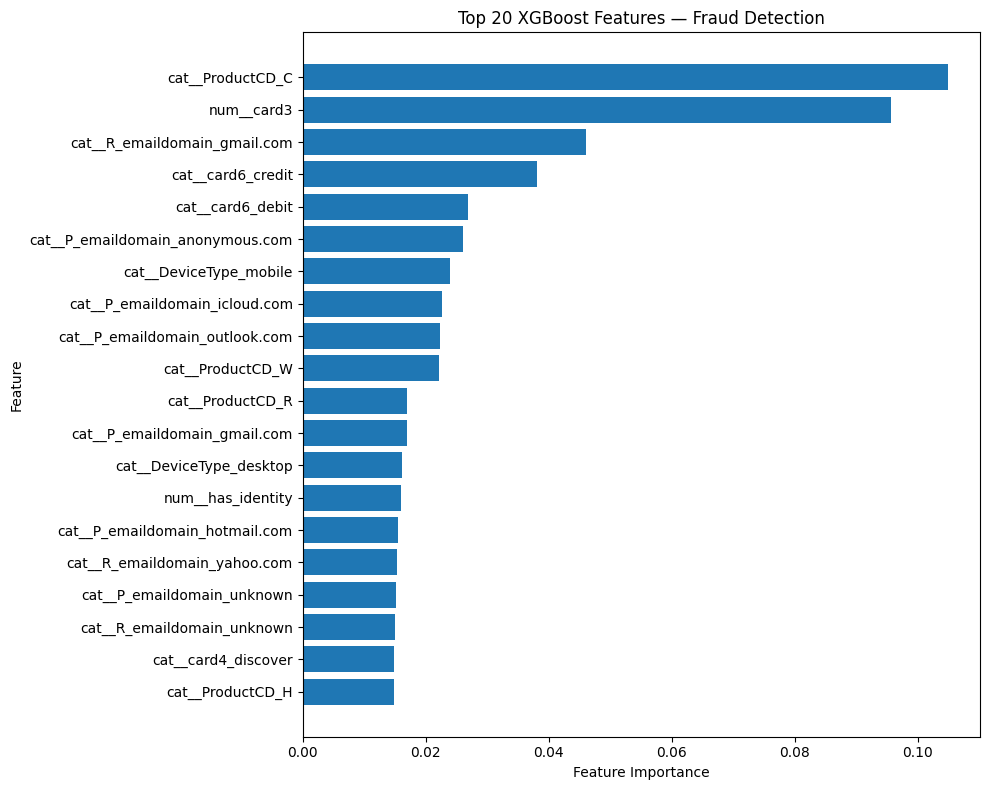

In [108]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Features — Fraud Detection")

plt.tight_layout()
plt.show()

In [109]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [110]:
import shap

xgb_classifier = xgb_model.named_steps["model"]

print("SHAP imported successfully.")

C:\Users\ANANT RAI\anaconda3\envs\datascience\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP imported successfully.


In [111]:
explainer = shap.TreeExplainer(xgb_classifier)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [112]:
X_test_transformed_sample = X_test_transformed[:500]

shap_values = explainer.shap_values(
    X_test_transformed_sample
)

print("SHAP values calculated successfully.")
print("Shape:", shap_values.shape)

SHAP values calculated successfully.
Shape: (500, 156)


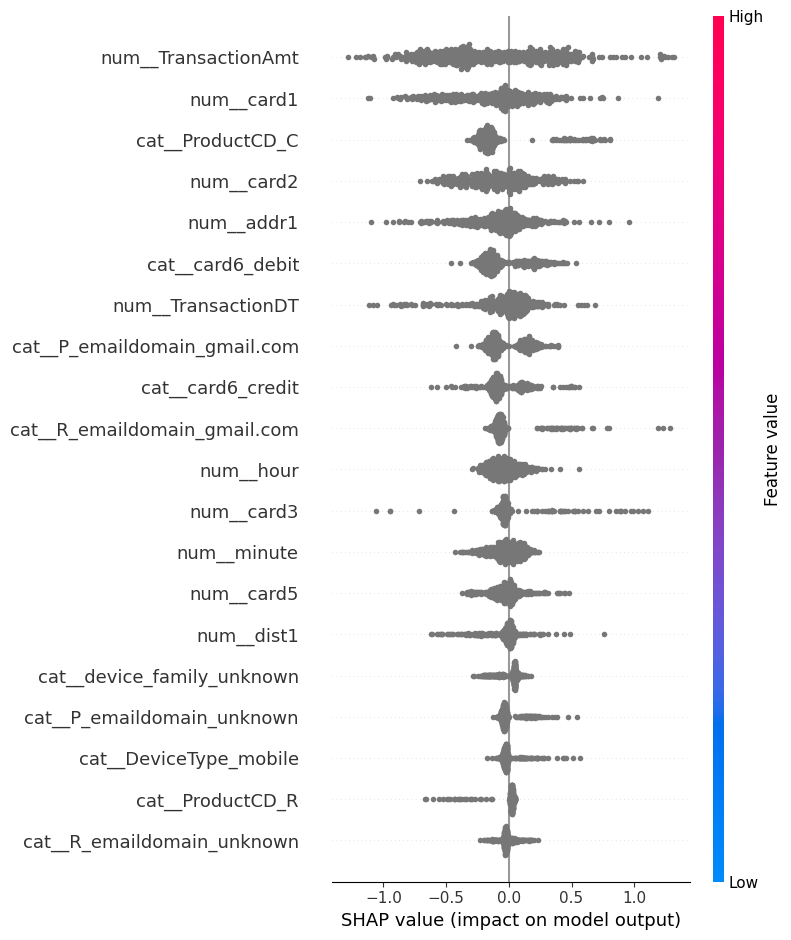

In [113]:
shap.summary_plot(
    shap_values,
    X_test_transformed_sample,
    feature_names=feature_names,
    show=True
)

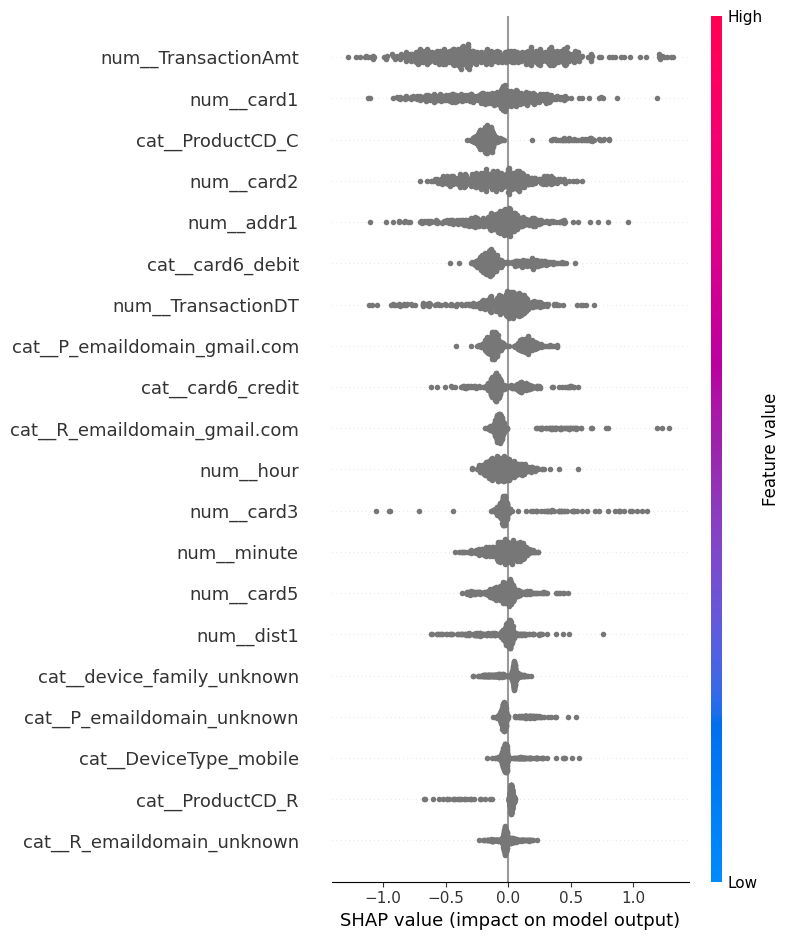

SHAP plot saved successfully.


In [114]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_test_transformed_sample,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()
plt.savefig(
    "../images/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP plot saved successfully.")

In [115]:
transaction_index = 0

single_shap_values = shap_values[transaction_index]

print("Transaction index:", transaction_index)
print("Actual fraud status:", y_test.iloc[transaction_index])
print(
    "Predicted fraud probability:",
    xgb_prob[transaction_index]
)

Transaction index: 0
Actual fraud status: 0
Predicted fraud probability: 0.0062668077


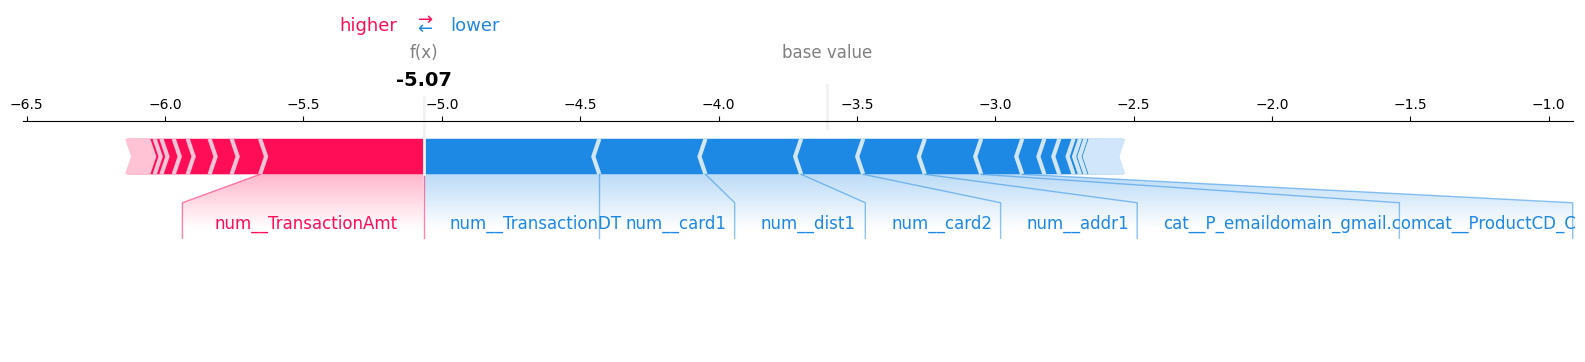

<Figure size 640x480 with 0 Axes>

In [118]:
single_features = X_test_transformed_sample[
    transaction_index
].toarray().flatten()

shap.force_plot(
    explainer.expected_value,
    single_shap_values,
    feature_names=feature_names,
    matplotlib=True
)

plt.tight_layout()
plt.show()

In [119]:
fraud_index = xgb_prob.argmax()

print("Transaction index:", fraud_index)
print("Actual fraud status:", y_test.iloc[fraud_index])
print(
    "Predicted fraud probability:",
    xgb_prob[fraud_index]
)

Transaction index: 2786
Actual fraud status: 1
Predicted fraud probability: 0.9309774


In [121]:
fraud_transformed = X_test_transformed[fraud_index]

fraud_shap_values = explainer.shap_values(
    fraud_transformed
)

fraud_features = fraud_transformed.toarray().flatten()

print("SHAP values calculated for fraudulent transaction.")
print("Number of features:", len(fraud_shap_values))

SHAP values calculated for fraudulent transaction.
Number of features: 1


In [124]:
fraud_shap_values = fraud_shap_values.flatten()

print("SHAP values shape:", fraud_shap_values.shape)
print("Number of features:", len(fraud_shap_values))

SHAP values shape: (156,)
Number of features: 156


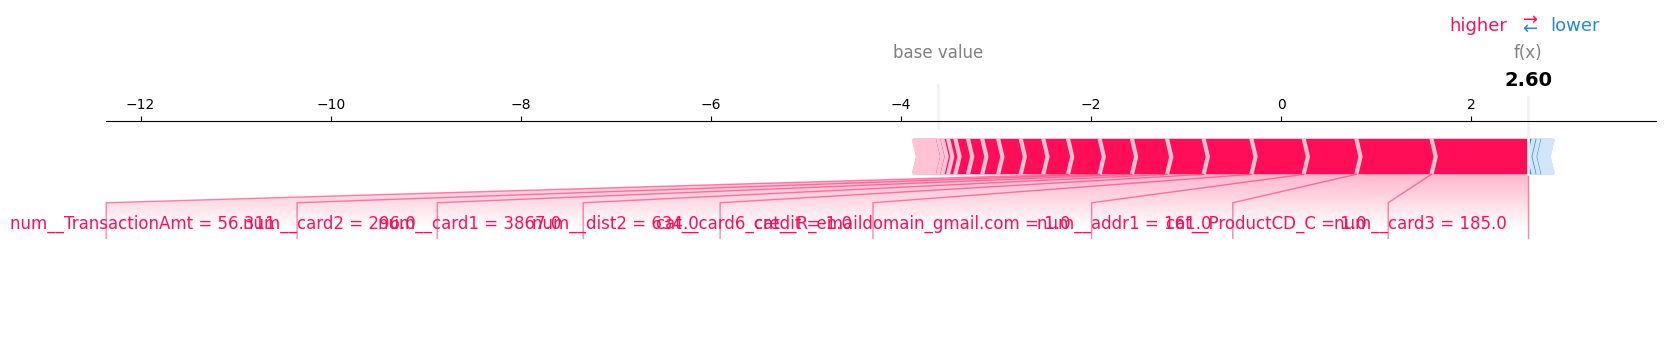

<Figure size 640x480 with 0 Axes>

In [126]:
shap.force_plot(
    explainer.expected_value,
    fraud_shap_values,
    fraud_features,
    feature_names=feature_names,
    matplotlib=True
)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

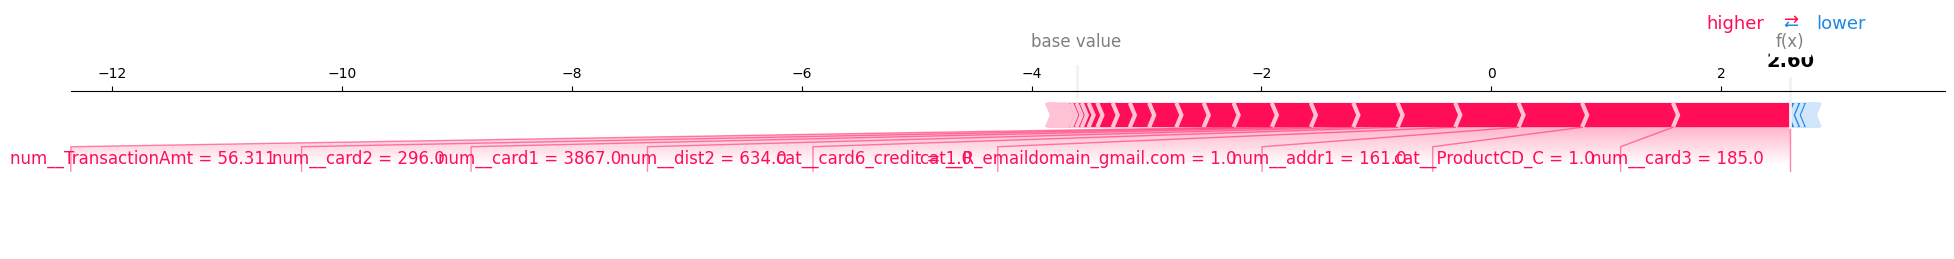

Fraud transaction SHAP plot saved successfully.


In [127]:
plt.figure()

shap.force_plot(
    explainer.expected_value,
    fraud_shap_values,
    fraud_features,
    feature_names=feature_names,
    matplotlib=True,
    show=False
)

plt.tight_layout()

plt.savefig(
    "../images/shap_fraud_transaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fraud transaction SHAP plot saved successfully.")

In [128]:
final_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Original XGBoost",
        "ROC-AUC": roc_auc_score(y_test, xgb_prob),
        "PR-AUC": average_precision_score(y_test, xgb_prob)
    },
    {
        "Model": "Tuned XGBoost",
        "ROC-AUC": roc_auc_score(y_test, xgb_tuned_prob),
        "PR-AUC": average_precision_score(y_test, xgb_tuned_prob)
    },
    {
        "Model": "Imbalance-aware XGBoost",
        "ROC-AUC": roc_auc_score(
            y_test,
            xgb_balanced_prob
        ),
        "PR-AUC": average_precision_score(
            y_test,
            xgb_balanced_prob
        )
    }
])

print(final_comparison)

                     Model   ROC-AUC    PR-AUC
0      Logistic Regression  0.769710  0.126501
1         Original XGBoost  0.902802  0.580967
2            Tuned XGBoost  0.891514  0.549138
3  Imbalance-aware XGBoost  0.897705  0.515194


In [130]:
import joblib

joblib.dump(
    xgb_model,
    "../models/fraudshield_xgb_model.pkl"
)

print("FraudShield XGBoost model saved successfully.")

FraudShield XGBoost model saved successfully.


In [131]:
loaded_model = joblib.load(
    "../models/fraudshield_xgb_model.pkl"
)

print("Model loaded successfully.")
print(type(loaded_model))

Model loaded successfully.
<class 'sklearn.pipeline.Pipeline'>


In [132]:
def predict_fraud(transaction_data):
    transaction_df = pd.DataFrame([transaction_data])

    fraud_probability = loaded_model.predict_proba(
        transaction_df
    )[0, 1]

    return fraud_probability


print("Prediction function created successfully.")

Prediction function created successfully.


In [133]:
sample_transaction = {
    "TransactionDT": 5000000,
    "TransactionAmt": 120.50,
    "card1": 12345,
    "card2": 111.0,
    "card3": 150.0,
    "card5": 226.0,
    "addr1": 315.0,
    "addr2": 87.0,
    "dist1": 10.0,
    "dist2": 5.0,
    "day_index": 57,
    "hour": 14,
    "minute": 30,
    "has_identity": 1,
    "ProductCD": "W",
    "card4": "visa",
    "card6": "credit",
    "P_emaildomain": "gmail.com",
    "R_emaildomain": "gmail.com",
    "DeviceType": "desktop",
    "device_family": "windows"
}

probability = predict_fraud(sample_transaction)

print("Fraud Probability:", probability)
print("Fraud Probability (%):", probability * 100)

Fraud Probability: 0.013122124
Fraud Probability (%): 1.3122123


In [134]:
def get_risk_level(probability):
    if probability < 0.20:
        return "LOW RISK"
    elif probability < 0.50:
        return "MEDIUM RISK"
    else:
        return "HIGH RISK"


risk_level = get_risk_level(probability)

print("Fraud Probability:", round(probability * 100, 2), "%")
print("Risk Level:", risk_level)

Fraud Probability: 1.31 %
Risk Level: LOW RISK


In [135]:
def get_risk_score(probability):
    return round(probability * 100)


risk_score = get_risk_score(probability)

print("Risk Score:", risk_score, "/ 100")

Risk Score: 1 / 100
